# 🎯 Phase 4.2 — Active Customer Scoring & Revenue at Risk
## PwC Technology Consulting | TelcoMax Customer Churn Engagement

**Objective:** Apply the trained predictive model to all **active customers (5,174 accounts)** to compute individual Churn Risk Scores (0.0 to 1.0), assign Risk Tiers (High, Medium, Low), and quantify annualized revenue exposure to guide commercial retention interventions.

---

In [1]:
import os
import sys
sys.path.insert(0, os.path.abspath(".."))

import joblib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from src.model_scoring import score_customers, export_scored_data, calculate_revenue_at_risk

# Load model artifacts
model = joblib.load(os.path.join("..", "models", "best_churn_model.joblib"))
scaler = joblib.load(os.path.join("..", "models", "scaler.joblib"))
feature_names = joblib.load(os.path.join("..", "models", "feature_names.joblib"))

# Load dataset and filter to active accounts
df_all = pd.read_csv(os.path.join("..", "data", "processed", "telco_churn_cleaned.csv"))
df_active = df_all[df_all["Churn"] == "No"].copy()
print(f"Active subscribers to score: {len(df_active):,} accounts")

Active subscribers to score: 5,174 accounts


### Section 1: Generate Churn Risk Scores & Risk Tiers
Apply probability scoring and segment into actionable risk tiers:
- **High Risk:** $\ge 0.70$
- **Medium Risk:** $0.40 \le \text{Score} < 0.70$
- **Low Risk:** $< 0.40$

In [2]:
df_scored = score_customers(model, df_active, feature_names, scaler)

# Export scored dataset
OUT_CSV = os.path.join("..", "data", "processed", "telco_churn_scored.csv")
export_scored_data(df_scored, OUT_CSV)
print(f"Scored dataset saved to: {OUT_CSV}")
print(df_scored[['customerID', 'MonthlyCharges', 'annualized_revenue', 'churn_risk_score', 'risk_tier']].head())

Scored dataset saved to: ..\data\processed\telco_churn_scored.csv
   customerID  MonthlyCharges  annualized_revenue  churn_risk_score  \
0  7590-VHVEG           29.85               358.2            0.6960   
1  5575-GNVDE           56.95               683.4            0.0564   
3  7795-CFOCW           42.30               507.6            0.0753   
6  1452-KIOVK           89.10              1069.2            0.4768   
7  6713-OKOMC           29.75               357.0            0.4772   

     risk_tier  
0  Medium Risk  
1     Low Risk  
3     Low Risk  
6  Medium Risk  
7  Medium Risk  


### Section 2: Portfolio Revenue Exposure Summary
Quantify annual revenue at risk across each customer risk tier.

In [3]:
risk_metrics = calculate_revenue_at_risk(df_scored)
summary_table = risk_metrics["summary_table"]
display(summary_table)

print(f"\nTotal Active Annual Revenue:       ${risk_metrics['total_annual_revenue']:,.2f}")
print(f"High-Risk Annual Revenue at Risk:  ${risk_metrics['high_risk_annual_revenue']:,.2f}")

,risk_tier,customer_count,total_monthly_spend,total_annual_revenue,avg_churn_risk,pct_of_customers,pct_of_revenue
0,High Risk,434,33878.55,406542.6,0.802636,8.39,10.69
1,Low Risk,3667,214836.35,2578036.2,0.110334,70.87,67.77
2,Medium Risk,1073,68270.85,819250.2,0.539574,20.74,21.54



Total Active Annual Revenue:       $3,803,829.00
High-Risk Annual Revenue at Risk:  $406,542.60


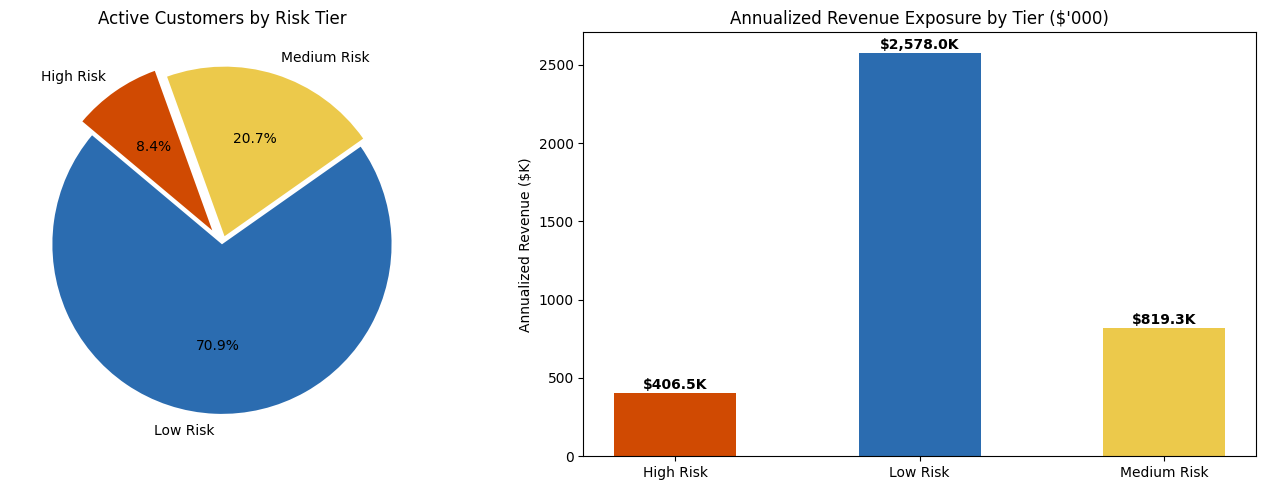

In [4]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Customer Breakdown by Tier
tier_counts = df_scored['risk_tier'].value_counts()
colors = ['#2B6CB0', '#ECC94B', '#D04A02']
ax1.pie(tier_counts.values, labels=tier_counts.index, autopct='%1.1f%%', colors=colors, startangle=140, explode=(0, 0.05, 0.1))
ax1.set_title("Active Customers by Risk Tier")

# Revenue Exposure by Tier
rev_by_tier = df_scored.groupby('risk_tier', observed=False)['annualized_revenue'].sum() / 1e3
bars = ax2.bar(rev_by_tier.index, rev_by_tier.values, color=['#D04A02', '#2B6CB0', '#ECC94B'], width=0.5)
for bar in bars:
    y = bar.get_height()
    ax2.text(bar.get_x() + bar.get_width()/2, y + 25, f"${y:,.1f}K", ha='center', fontweight='bold')
ax2.set_title("Annualized Revenue Exposure by Tier ($'000)")
ax2.set_ylabel("Annualized Revenue ($K)")

plt.tight_layout()
plt.show()

### Section 3: High-Priority Intervention Target List
Identify top 20 highest-value active subscribers in the High-Risk category for immediate retention outreach.

In [5]:
top_20_targets = df_scored[df_scored['risk_tier'] == 'High Risk'].sort_values('MonthlyCharges', ascending=False).head(20)
display(top_20_targets[['customerID', 'Contract', 'tenure', 'InternetService', 'MonthlyCharges', 'annualized_revenue', 'churn_risk_score']])

,customerID,Contract,tenure,InternetService,MonthlyCharges,annualized_revenue,churn_risk_score
1568,3292-PBZEJ,Month-to-month,11,Fiber optic,111.40,1336.8,0.8472
678,5760-IFJOZ,Month-to-month,3,Fiber optic,107.95,1295.4,0.8721
1719,2081-VEYEH,Month-to-month,3,Fiber optic,107.95,1295.4,0.8815
5444,1833-TCXKK,Month-to-month,45,Fiber optic,107.75,1293.0,0.7934
511,8535-SFUTN,Month-to-month,61,Fiber optic,106.45,1277.4,0.7000
5795,7048-GXDAY,Month-to-month,39,Fiber optic,106.40,1276.8,0.7009
2474,5630-IXDXV,Month-to-month,47,Fiber optic,106.35,1276.2,0.7476
4572,6377-WHAOX,Month-to-month,60,Fiber optic,106.15,1273.8,0.7105
2582,7145-FEJWU,Month-to-month,12,Fiber optic,105.30,1263.6,0.8383
2387,6734-GMPVK,Month-to-month,5,Fiber optic,105.30,1263.6,0.8985
